<a href="https://colab.research.google.com/github/mwangimarie43-art/100-days-ai-journey/blob/main/decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Trees, Imbalanced Classes and Random Forests

**Contents**

1. Introduction to decision trees
2. **Classification trees** – splitting criteria (Gini, entropy), evaluation metrics, a first model, visualisation, and how the tunable hyperparameters change performance
3. **Regression trees** – the MSE splitting rule, depth/leaf-size tuning and cost-complexity (post-)pruning
4. **Imbalanced classes** – why trees struggle and how to fix it (class weights, resampling, threshold moving, the right metrics)
5. **Ensemble learning** – what it is, then random forests in depth (vs CART on classification and regression, tunable parameters, imbalanced data), and a brief overview of the other ensemble methods
6. Pros and cons, and a hyperparameter cheat-sheet

---

# 1. Introduction

* Decision trees are supervised learning algorithms used for both **classification** and **regression**.
* The idea is to find the descriptive features that carry the most **information** about the target, and split the data along their values so that the resulting subsets are as **pure** (homogeneous in the target) as possible.
* Splitting is repeated recursively until a **stopping criterion** is met; the final nodes are called **leaf nodes**.

## Anatomy of a tree

* **Root node** – the first split, containing all the training data.
* **Interior (decision) nodes** – each tests one feature, e.g. `petal length ≤ 2.45`.
* **Branches** – the outcomes of a test.
* **Leaves** – hold the prediction: the majority class (classification) or the mean response (regression) of the training samples that end up there.

A new instance is classified by starting at the root, applying the test, following the matching branch, and repeating until a leaf is reached.

## Training in four steps

1. Present a dataset of instances described by features and a target.
2. Recursively split the data using the feature/threshold that most reduces impurity (**greedy**, top-down: the best split *now* is chosen, without looking ahead).
3. Stop when a stopping criterion is met (max depth, minimum samples per leaf, pure node, …).
4. Predict by dropping new instances down the tree to a leaf.

The algorithm used by scikit-learn is an optimised version of **CART** (Classification And Regression Trees), which always makes **binary** splits.

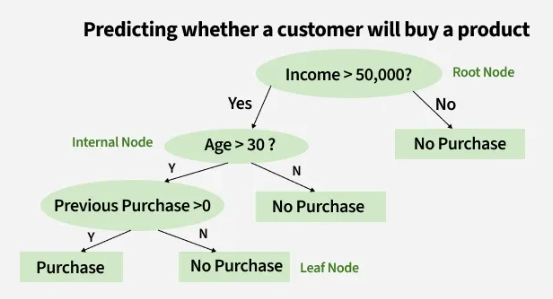

In [ ]:
#--data manipulation
import numpy as np
import pandas as pd
import time

#--datasets
from sklearn.datasets import (load_iris, load_breast_cancer,
                              fetch_california_housing, make_classification)

#--models
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor,plot_tree
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              BaggingClassifier)

#--model selection
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     cross_val_predict, GridSearchCV,
                                     StratifiedKFold, RepeatedStratifiedKFold,
                                     KFold, validation_curve)
from sklearn.utils import resample
from sklearn.inspection import permutation_importance

#--metrics
from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score, precision_recall_curve
)

#--plotting
import matplotlib
import matplotlib.pyplot as plt
%matplotlib inline
matplotlib.rcParams['font.size'] = 11
matplotlib.rcParams['figure.titlesize'] = 12

SEED = 42

---
# 2. Classification trees

A classification tree predicts a **categorical** outcome. Each leaf predicts the most frequent class among the training samples that land in it, and the class proportions in the leaf give `predict_proba`.

## 2.1 How a split is chosen: impurity measures

For a node with class proportions $p_1,\dots,p_K$:

* **Gini impurity** (scikit-learn default):
$$G = 1-\sum_{k=1}^{K} p_k^2$$
* **Entropy**:
$$H = -\sum_{k=1}^{K} p_k \log_2 p_k$$

Both are 0 for a pure node and largest when classes are equally mixed (Gini = 0.5, entropy = 1 for two classes).

A candidate split sends $n_L$ samples left and $n_R$ right. Its quality is the **weighted** impurity of the children,

$$G_{\text{split}} = \frac{n_L}{n}G_L + \frac{n_R}{n}G_R ,$$

and the tree picks the feature/threshold that gives the largest **impurity decrease** $G_{\text{parent}} - G_{\text{split}}$ (with entropy this decrease is called the **information gain**).


## 2.2 Evaluating a classifier: the confusion matrix

|             | Predicted no | Predicted yes |
| :---------- | :----------- | :------------ |
| Actual no   | 50 (TN)      | 10 (FP)       |
| Actual yes  | 5 (FN)       | 100 (TP)      |

Suppose we test 165 patients for a disease ("yes" = has the disease):

* **TP** – predicted yes, has the disease; **TN** – predicted no, does not.
* **FP** – predicted yes, but healthy (Type I error); **FN** – predicted no, but ill (Type II error).

| Metric | Formula | Value |
|---|---|---|
| Accuracy | (TP+TN)/total | 150/165 = 0.91 |
| Error rate | (FP+FN)/total | 15/165 = 0.09 |
| Recall / sensitivity / TPR | TP/(TP+FN) | 100/105 = 0.95 |
| Specificity / TNR | TN/(TN+FP) | 50/60 = 0.83 |
| False positive rate | FP/(TN+FP) | 10/60 = 0.17 |
| Precision | TP/(TP+FP) | 100/110 = 0.91 |
| F1 score | 2·P·R/(P+R) | 0.93 |
| Balanced accuracy | (TPR+TNR)/2 | 0.89 |

**Why accuracy alone is not enough:** if 95% of patients were healthy, a model that always says "no" would score 95% accuracy while catching *no* sick patients. Recall, precision, F1, balanced accuracy and the precision–recall curve are what we use for imbalanced problems (Section 4).

## 2.3 A first classification tree: iris

We split with `stratify=y` so that every class keeps its proportion in train and test, then look at how tree depth affects train vs. test accuracy.

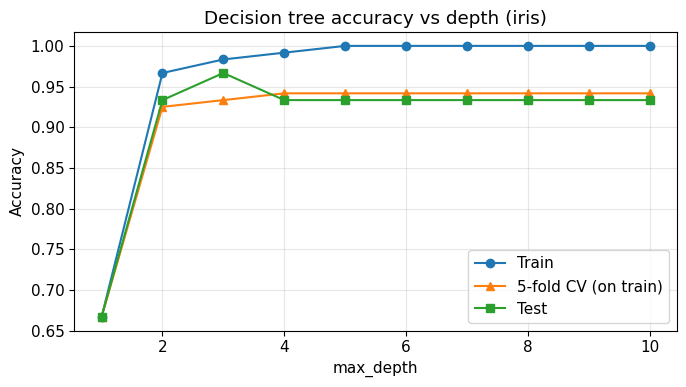

Depth chosen by CV: 4
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion matrix:
 [[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [ ]:
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

depths = range(1, 11)
train_acc, test_acc, cv_acc = [], [], []
for d in depths:
    clf = DecisionTreeClassifier(max_depth=d,
                                 random_state=SEED).fit(X_train, y_train)
    train_acc.append(clf.score(X_train, y_train))
    test_acc.append(clf.score(X_test, y_test))
    cv_acc.append(cross_val_score(DecisionTreeClassifier(max_depth=d,
                                  random_state=SEED),
                                  X_train, y_train, cv=5).mean())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(depths, train_acc, marker='o', label='Train')
ax.plot(depths, cv_acc, marker='^', label='5-fold CV (on train)')
ax.plot(depths, test_acc, marker='s', label='Test')
ax.set_xlabel('max_depth'); ax.set_ylabel('Accuracy')
ax.set_title('Decision tree accuracy vs depth (iris)')
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

#--choose depth by cross-validation on the training set, NOT by the test set
best_depth = list(depths)[int(np.argmax(cv_acc))]
best_model = DecisionTreeClassifier(max_depth=best_depth,
                                  random_state=SEED).fit(X_train, y_train)
pred = best_model.predict(X_test)
print(f"Depth chosen by CV: {best_depth}")
print(classification_report(y_test, pred, target_names=iris.target_names))
print("Confusion matrix:\n", confusion_matrix(y_test, pred))

**Remarks**

* Training accuracy keeps rising with depth – a fully grown tree reaches 100% on the training data because it can isolate every point.
* The depth is chosen with **cross-validation on the training set**. Picking the depth that maximises *test* accuracy (as is often done) leaks test information into model selection and gives an optimistic estimate.
* Iris is small and well separated, so the test score on 30 flowers is noisy; a single misclassified flower moves accuracy by 3.3 percentage points. That is why cross-validated scores are more reliable.

## 2.4 Visualising the tree

Trees are "white-box" models: we can draw them and read off the rules. Each node shows the split, the impurity, the number of samples, the class counts and the majority class. `plot_tree` needs no extra software (Graphviz is optional).

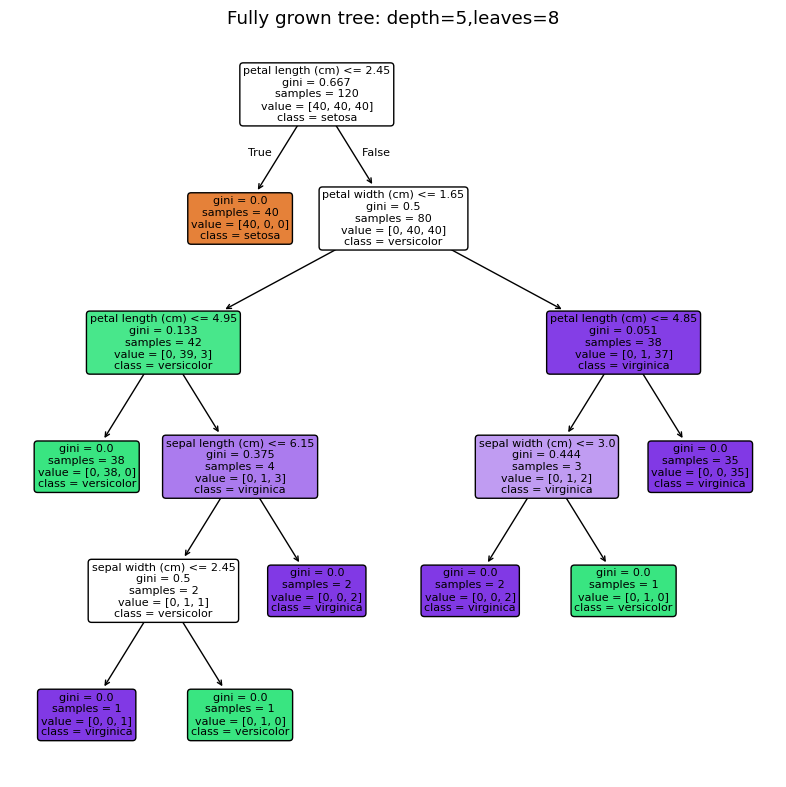

Full tree   train=1.000  test=0.933


In [ ]:
#--fully grown tree (no limits)
full_tree = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(8, 8))
plot_tree(full_tree, feature_names=iris.feature_names,
          class_names=iris.target_names,
          filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f"Fully grown tree: depth={full_tree.get_depth()},leaves={full_tree.get_n_leaves()}")
plt.tight_layout(); plt.show()

print(f"Full tree   train={full_tree.score(X_train,
                    y_train):.3f}  test={full_tree.score(X_test, y_test):.3f}")

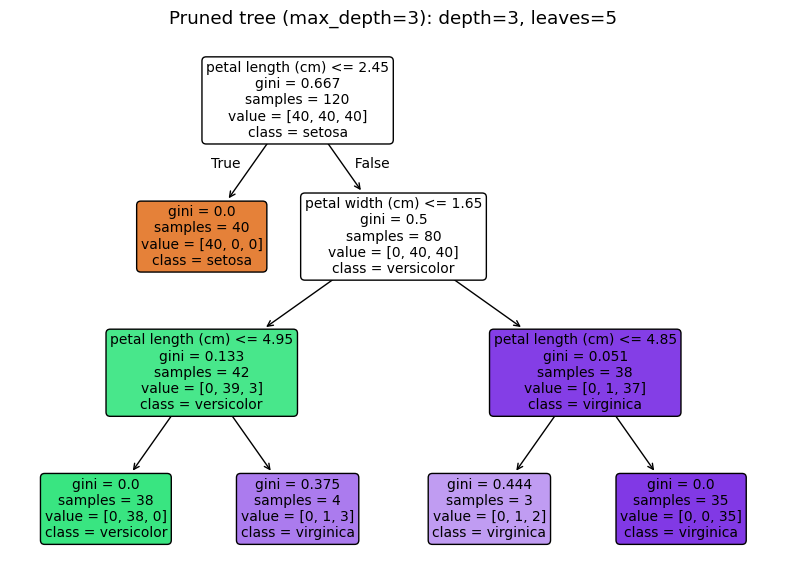

Pruned tree train=0.983  test=0.967


In [ ]:
#--pruned tree (depth limited to 3)
pruned_tree = DecisionTreeClassifier(max_depth=3,
                                     random_state=SEED).fit(X_train, y_train)

fig, ax = plt.subplots(figsize=(8, 6))
plot_tree(pruned_tree, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title(f"Pruned tree (max_depth=3): depth={pruned_tree.get_depth()}, leaves={pruned_tree.get_n_leaves()}")
plt.tight_layout(); plt.show()

print(f"Pruned tree train={pruned_tree.score(X_train,
                  y_train):.3f}  test={pruned_tree.score(X_test, y_test):.3f}")

The deep branches of the full tree split nodes with only 1–3 samples – they are fitting noise. The pruned tree is far easier to read and generalises at least as well.

## 2.5 Overfitting and the tunable hyperparameters

A tree grown until every leaf is pure has **low bias but very high variance**: it memorises the training data, and small changes in the data produce a very different tree. We control complexity with these `DecisionTreeClassifier` parameters:

| Parameter | What it does | Effect of increasing it |
|---|---|---|
| `criterion` | `'gini'`, `'entropy'` or `'log_loss'` | Usually a small effect |
| `max_depth` | Maximum number of levels | More complex, more overfitting |
| `min_samples_split` | Minimum samples a node needs before it may be split | Simpler tree |
| `min_samples_leaf` | Minimum samples allowed in each leaf | Simpler, smoother tree (very effective) |
| `max_leaf_nodes` | Grow best-first up to this many leaves | More complex |
| `min_impurity_decrease` | A split must reduce impurity by at least this much | Simpler tree |
| `max_features` | Number of features considered at each split | Fewer features → more randomness (key for random forests) |
| `ccp_alpha` | Cost-complexity **post-pruning** strength | Simpler tree |
| `class_weight` | Re-weights classes in the impurity calculation | Used for imbalanced data (Section 4) |

All but `ccp_alpha` act as **pre-pruning** (they stop growth early); `ccp_alpha` grows the full tree and then cuts it back (**post-pruning**, see Section 3.3).

Iris is too easy to show these effects, so we switch to the **breast cancer** dataset (569 tumours, 30 features, malignant vs benign).

max_depth              best = 3        CV accuracy = 0.939
min_samples_leaf       best = 8        CV accuracy = 0.934
min_samples_split      best = 20       CV accuracy = 0.930
max_leaf_nodes         best = 6        CV accuracy = 0.944
min_impurity_decrease  best = 0.01     CV accuracy = 0.941
criterion              best = entropy  CV accuracy = 0.930


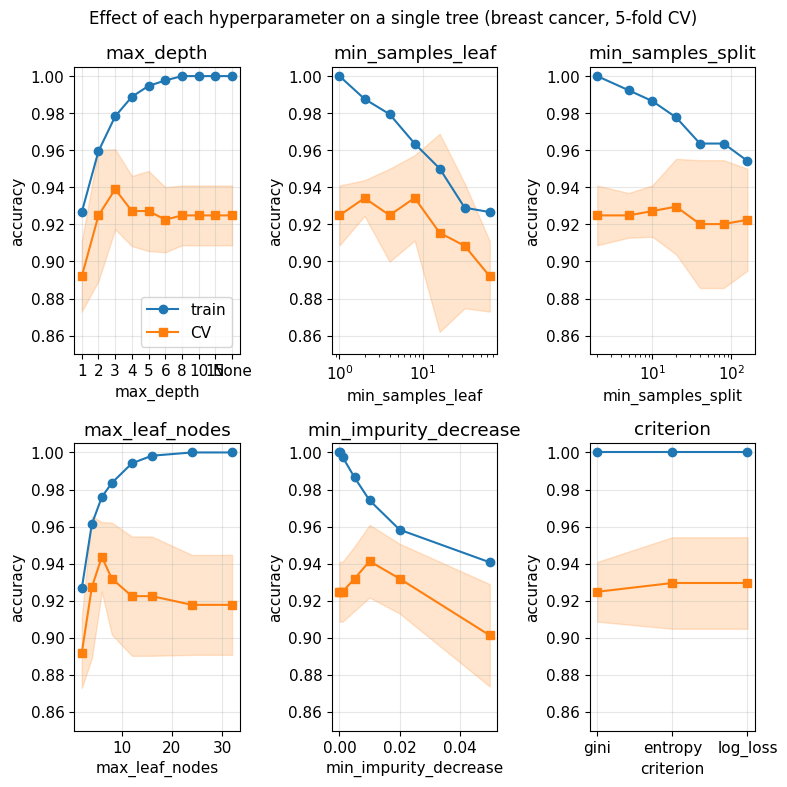

In [ ]:
cancer = load_breast_cancer()
Xc, yc = cancer.data, cancer.target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.25, random_state=SEED, stratify=yc)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def plot_validation(estimator, param, values, X, y, ax, scoring='accuracy',
                    log=False, label=None):
    tr, va = validation_curve(estimator, X, y, param_name=param, param_range=values,
                              cv=cv5, scoring=scoring, n_jobs=-1)
    x = [str(v) for v in values] if not np.issubdtype(np.array(values).dtype,
                                                      np.number) else values
    ax.plot(x, tr.mean(1), 'o-', label='train')
    ax.plot(x, va.mean(1), 's-', label='CV')
    ax.fill_between(x, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2,
                    color='C1')
    if log: ax.set_xscale('log')
    ax.set_title(label or param); ax.set_xlabel(param); ax.grid(alpha=.3)
    best = values[int(np.argmax(va.mean(1)))]
    return best, va.mean(1).max()

base = DecisionTreeClassifier(random_state=SEED)
settings = [
    ('max_depth',             [1, 2, 3, 4, 5, 6, 8, 10, 15, None], False),
    ('min_samples_leaf',      [1, 2, 4, 8, 16, 32, 64],             True),
    ('min_samples_split',     [2, 5, 10, 20, 40, 80, 160],          True),
    ('max_leaf_nodes',        [2, 4, 6, 8, 12, 16, 24, 32],         False),
    ('min_impurity_decrease', [0, 1e-4, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2], False),
    ('criterion',             ['gini', 'entropy', 'log_loss'],      False),
]
fig, axes = plt.subplots(2, 3, figsize=(8, 8))
for ax, (param, vals, log) in zip(axes.ravel(), settings):
    vals_plot = [v if v is not None else 'None' for v in vals] if param == 'max_depth' else vals
    if param == 'max_depth':
        tr, va = validation_curve(base, Xc_train, yc_train, param_name=param,
                                  param_range=vals, cv=cv5, n_jobs=-1)
        xs = [str(v) for v in vals_plot]
        ax.plot(xs, tr.mean(1), 'o-', label='train'); ax.plot(xs, va.mean(1), 's-', label='CV')
        ax.fill_between(xs, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2, color='C1')
        ax.set_title(param); ax.set_xlabel(param); ax.grid(alpha=.3)
        best, score = vals[int(np.argmax(va.mean(1)))], va.mean(1).max()
    else:
        best, score = plot_validation(base, param, vals, Xc_train, yc_train, ax, log=log)
    ax.set_ylabel('accuracy'); ax.set_ylim(0.85, 1.005)
    print(f"{param:<22} best = {str(best):<8} CV accuracy = {score:.3f}")
axes[0, 0].legend()
fig.suptitle('Effect of each hyperparameter on a single tree (breast cancer, 5-fold CV)')
plt.tight_layout(); plt.show()

**Reading the curves**

* With little constraint (large depth, `min_samples_leaf=1`, `min_samples_split=2`), training accuracy is 1.0 but CV accuracy is lower – **overfitting**.
* Too much constraint (`max_depth=1`, `min_samples_leaf=64`) lowers both – **underfitting**.
* The sweet spot is in between. The choice of `criterion` makes little difference here.
* The CV band is wide: single trees are **unstable** (high variance). Keep this in mind for Section 5.

Parameters interact, so in practice we tune them **jointly** with `GridSearchCV`:

In [ ]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 4, 5, 6, None],
    'min_samples_leaf': [1, 3, 5, 10, 20],
    'ccp_alpha': [0.0, 0.005, 0.01],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid,
                    cv=cv5, scoring='accuracy', n_jobs=-1).fit(Xc_train, yc_train)

print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.3f}")
best_cart = grid.best_estimator_
print(f"Test accuracy of tuned tree: {best_cart.score(Xc_test, yc_test):.3f}")
print(f"Test accuracy of default (unpruned) tree: "
      f"{DecisionTreeClassifier(random_state=SEED).fit(Xc_train, yc_train).score(Xc_test, yc_test):.3f}")

#--top 5 parameter combinations
res = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')
res[['params', 'mean_test_score', 'std_test_score']].head(5)

Best parameters: {'ccp_alpha': 0.01, 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}
Best CV accuracy: 0.941
Test accuracy of tuned tree: 0.944
Test accuracy of default (unpruned) tree: 0.923


,params,mean_test_score,std_test_score
120,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",0.941341,0.019591
121,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",0.941341,0.019591
106,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",0.941341,0.019591
105,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",0.941341,0.019591
111,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",0.941341,0.019591


### Instability of a single tree

Re-fitting the *same* tree on slightly different samples of the data (bootstrap samples) gives noticeably different trees and test scores. This high variance is the motivation for ensembles.

---
# 3. Regression trees

## 3.1 Building a regression tree

1. Split the predictor space (the possible values of $x_1,\dots,x_p$) into $J$ distinct, **non-overlapping** regions $R_1,\dots,R_J$ (axis-aligned boxes).
2. For every observation that falls in $R_j$, predict the **mean response** $\bar y_{R_j}$ of the training observations in $R_j$.

The ideal boxes minimise the residual sum of squares

$$\mathrm{RSS} = \sum_{j=1}^{J}\sum_{i\in R_j}\left(y_i-\bar y_{R_j}\right)^2 .$$

Checking every possible partition is computationally infeasible, so we use **recursive binary splitting**: top-down (start with all observations in one region) and greedy (take the best split at each step).

At each step we choose the predictor $x_j$ and cut-point $s$ that define the half-planes

$$R_1(j,s)=\{X \mid x_j < s\}, \qquad R_2(j,s)=\{X \mid x_j \ge s\},$$

and minimise

$$\sum_{i:\,x_i\in R_1}\left(y_i-\bar y_{R_1}\right)^2+\sum_{i:\,x_i\in R_2}\left(y_i-\bar y_{R_2}\right)^2 .$$

The search covers all predictors and all cut-points (in practice, midpoints between consecutive sorted values). We then repeat the procedure inside one of the resulting regions, and so on, until a stopping criterion is reached (e.g. no region with more than five observations).

The node impurity used by scikit-learn (`criterion='squared_error'`) is the node MSE

$$\mathrm{MSE}_{\text{node}}=\frac{1}{m_{\text{node}}}\sum_{i\in\text{node}}\left(y_i-\bar y_{\text{node}}\right)^2, \qquad \bar y_{\text{node}}=\frac{1}{m_{\text{node}}}\sum_{i\in\text{node}}y_i .$$

Other options are `'absolute_error'` (median in each leaf, robust to outliers), `'friedman_mse'` and `'poisson'`.

## 3.2 Regression tree on the California housing data

Target: median house value per district, converted to k\$. Features: median income, house age, rooms, location, …

max_depth=4  RMSE: 80.15 k$   R²: 0.510


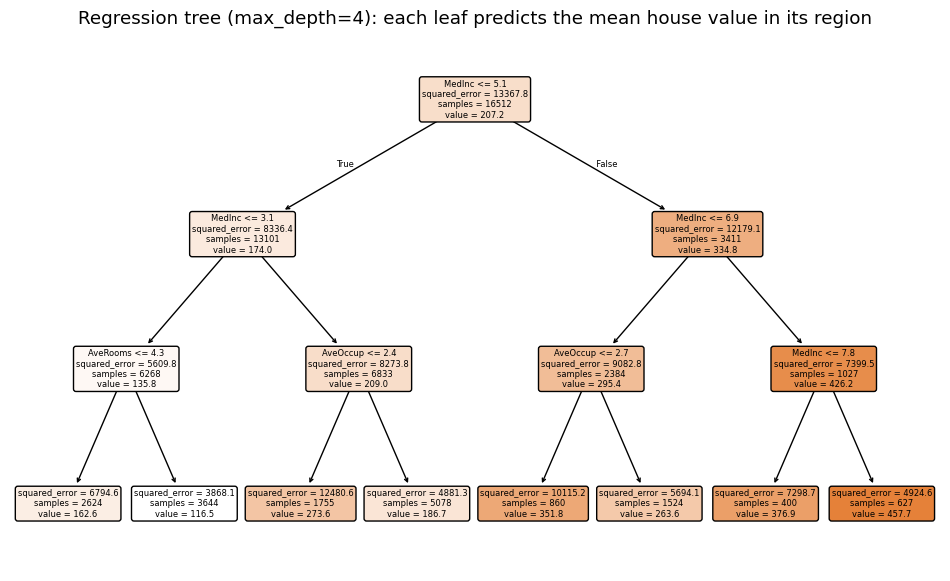

In [ ]:
data, target = fetch_california_housing(as_frame=True, return_X_y=True)
target = target * 100        #--convert to k$
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    data, target, test_size=0.2, random_state=SEED)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

reg = DecisionTreeRegressor(max_depth=3,
                        random_state=SEED).fit(Xh_train, yh_train)
yh_pred = reg.predict(Xh_test)
print(f"max_depth=4  RMSE: {rmse(yh_test,
                      yh_pred):.2f} k$   R²: {r2_score(yh_test, yh_pred):.3f}")

fig, ax = plt.subplots(figsize=(12, 7))
plot_tree(reg, feature_names=data.columns, filled=True, rounded=True, fontsize=6,
          precision=1, ax=ax)
ax.set_title('Regression tree (max_depth=4): each leaf predicts the mean house value in its region')
plt.show()

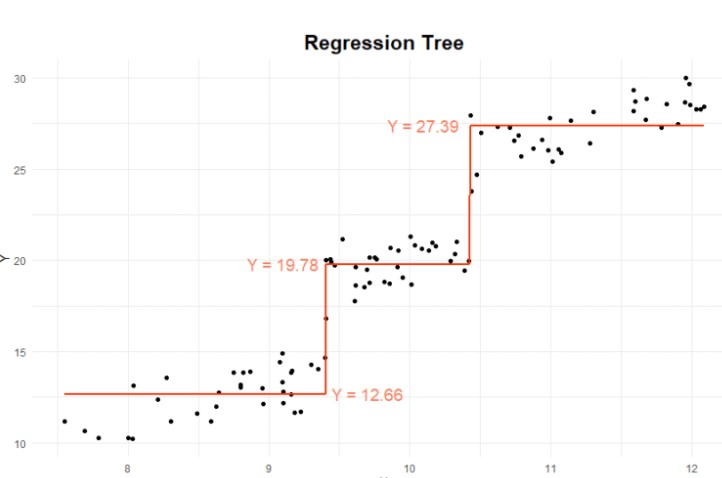

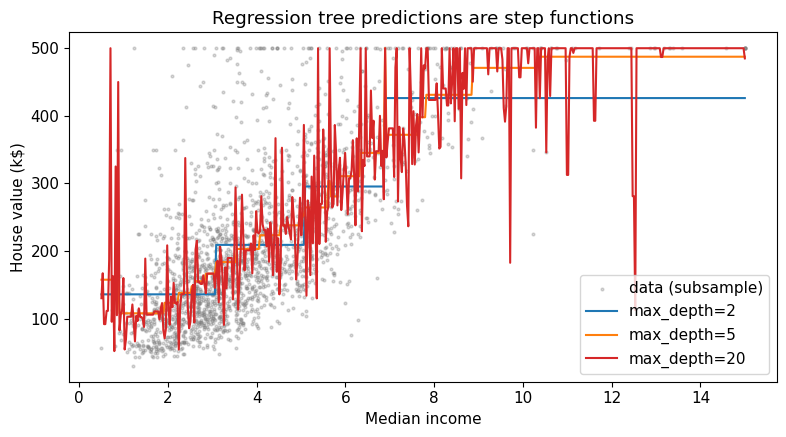

In [ ]:
x1 = Xh_train[['MedInc']]
grid_x = pd.DataFrame({'MedInc': np.linspace(x1.min().iloc[0], x1.max().iloc[0], 500)})
fig, ax = plt.subplots(figsize=(8, 4.5))
sub = np.random.RandomState(SEED).choice(len(x1), 2000, replace=False)
ax.scatter(x1.iloc[sub], yh_train.iloc[sub], s=4, alpha=.3, color='gray',
           label='data (subsample)')
for d, c in [(2, 'C0'), (5, 'C1'), (20, 'C3')]:
    m = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(x1, yh_train)
    ax.plot(grid_x, m.predict(grid_x), color=c, lw=1.5, label=f'max_depth={d}')
ax.set_xlabel('Median income'); ax.set_ylabel('House value (k$)')
ax.set_title('Regression tree predictions are step functions'); ax.legend()
plt.tight_layout(); plt.show()

Depth 2 is too coarse (underfit), depth 20 follows individual noisy points (overfit). Next we quantify the effect of `max_depth` and `min_samples_leaf` on train and test RMSE.

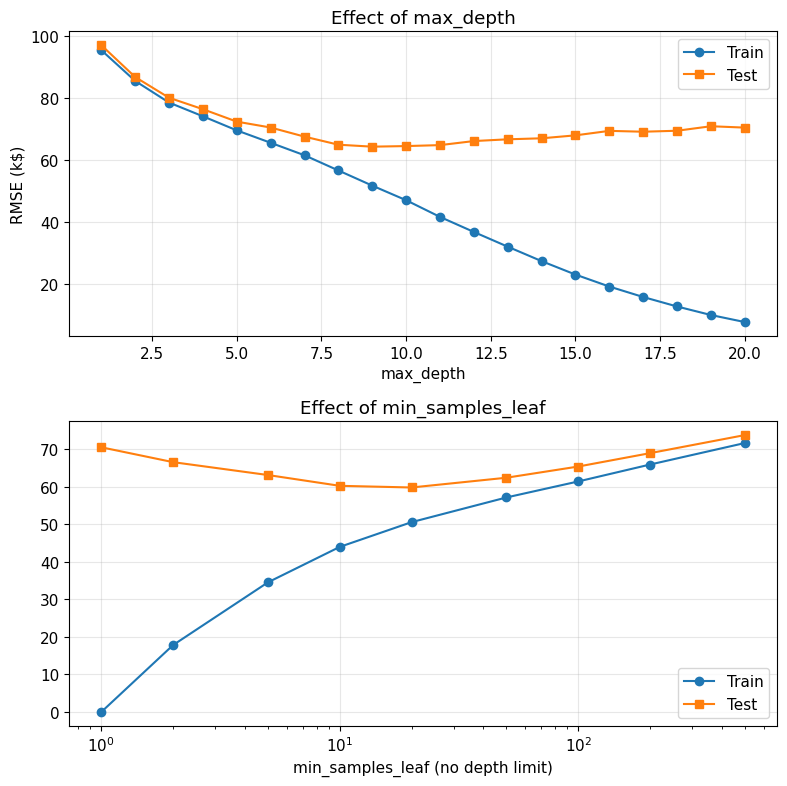

Best test RMSE over depth: 64.33 k$ at max_depth=9
Best test RMSE over min_samples_leaf: 59.78 k$ at min_samples_leaf=20


In [ ]:
depths = list(range(1, 21))
tr_rmse, te_rmse = [], []
for d in depths:
    m = DecisionTreeRegressor(max_depth=d, random_state=SEED).fit(Xh_train, yh_train)
    tr_rmse.append(rmse(yh_train, m.predict(Xh_train)))
    te_rmse.append(rmse(yh_test, m.predict(Xh_test)))

leaves = [1, 2, 5, 10, 20, 50, 100, 200, 500]
tr_leaf, te_leaf = [], []
for l in leaves:
    m = DecisionTreeRegressor(min_samples_leaf=l,
                              random_state=SEED).fit(Xh_train, yh_train)
    tr_leaf.append(rmse(yh_train, m.predict(Xh_train)))
    te_leaf.append(rmse(yh_test, m.predict(Xh_test)))

fig, axes = plt.subplots(2, 1, figsize=(8, 8))
axes[0].plot(depths, tr_rmse, 'o-', label='Train');
axes[0].plot(depths, te_rmse, 's-', label='Test')
axes[0].set_xlabel('max_depth'); axes[0].set_ylabel('RMSE (k$)')
axes[0].set_title('Effect of max_depth')
axes[1].plot(leaves, tr_leaf, 'o-', label='Train'); axes[1].plot(leaves,
                                                    te_leaf, 's-', label='Test')
axes[1].set_xscale('log');axes[1].set_xlabel('min_samples_leaf (no depth limit)')
axes[1].set_title('Effect of min_samples_leaf')
for ax in axes: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"Best test RMSE over depth: {min(te_rmse):.2f} k$ at max_depth={depths[int(np.argmin(te_rmse))]}")
print(f"Best test RMSE over min_samples_leaf: {min(te_leaf):.2f} k$ at min_samples_leaf={leaves[int(np.argmin(te_leaf))]}")

The classic U-shape: test error falls as the tree grows, reaches a minimum at an intermediate depth (or leaf size), then rises again as the tree starts fitting noise, while training error keeps falling towards zero. Constraining `min_samples_leaf` is often a better regulariser than `max_depth`, because it lets the tree grow deep where there is plenty of data and keeps it coarse where data is sparse.

## 3.3 Cost-complexity (post-)pruning

Instead of stopping growth early, we can grow a large tree $T_0$ and **prune** it back. For a non-negative tuning parameter $\alpha$ we seek the subtree $T\subseteq T_0$ minimising

$$\sum_{m=1}^{|T|}\sum_{i:\,x_i\in R_m}\left(y_i-\bar y_{R_m}\right)^2+\alpha|T|,$$

where $|T|$ is the number of leaves. $\alpha=0$ gives the full tree; increasing $\alpha$ penalises leaves and produces a nested sequence of ever-smaller subtrees. $\alpha$ is chosen by cross-validation.

scikit-learn implements this through the `ccp_alpha` parameter (available since version 0.22), and `cost_complexity_pruning_path` returns the candidate $\alpha$ values. See the [scikit-learn pruning example](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html).

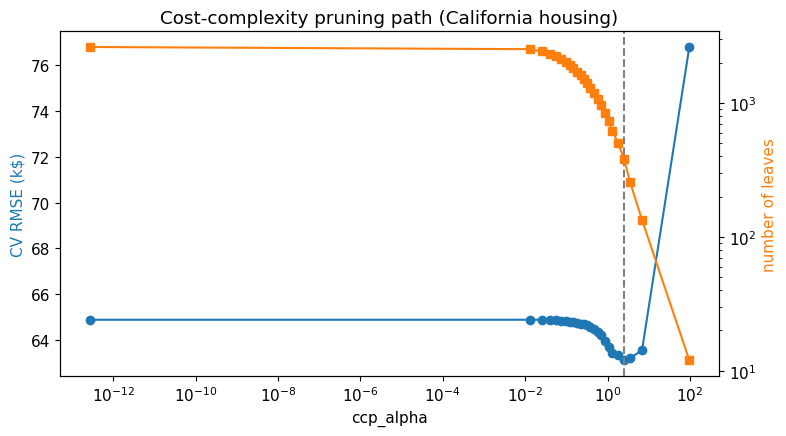

Best alpha = 2.51: 384 leaves, test RMSE = 60.97 k$, R² = 0.716


In [ ]:
path = DecisionTreeRegressor(random_state=SEED,
          min_samples_leaf=5).cost_complexity_pruning_path(Xh_train, yh_train)
#--the path has thousands of alphas; evaluate a log-spaced subset
alphas = np.unique(np.quantile(path.ccp_alphas[path.ccp_alphas > 0],
                               np.linspace(0, 0.995, 25)))

cv_rmse, n_leaves = [], []
kf = KFold(5, shuffle=True, random_state=SEED)
for a in alphas:
    m = DecisionTreeRegressor(random_state=SEED, min_samples_leaf=5, ccp_alpha=a)
    cv_rmse.append(-cross_val_score(m, Xh_train, yh_train, cv=kf,
                                    scoring='neg_root_mean_squared_error',
                                    n_jobs=-1).mean())
    n_leaves.append(m.fit(Xh_train, yh_train).get_n_leaves())

best_alpha = alphas[int(np.argmin(cv_rmse))]
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(alphas, cv_rmse, 'o-', color='C0'); ax1.set_xscale('log')
ax1.set_xlabel('ccp_alpha'); ax1.set_ylabel('CV RMSE (k$)', color='C0')
ax1.axvline(best_alpha, color='gray', ls='--')
ax2 = ax1.twinx(); ax2.plot(alphas, n_leaves, 's-',
                            color='C1'); ax2.set_yscale('log')
ax2.set_ylabel('number of leaves', color='C1')
ax1.set_title('Cost-complexity pruning path (California housing)')
plt.tight_layout(); plt.show()

pruned_reg = DecisionTreeRegressor(random_state=SEED, min_samples_leaf=5,
                                   ccp_alpha=best_alpha).fit(Xh_train, yh_train)
cart_reg_rmse = rmse(yh_test, pruned_reg.predict(Xh_test))
print(f"Best alpha = {best_alpha:.2f}: {pruned_reg.get_n_leaves()} leaves, "
      f"test RMSE = {cart_reg_rmse:.2f} k$, R² = {r2_score(yh_test,
                                            pruned_reg.predict(Xh_test)):.3f}")

---
# 4. Imbalanced classes

A dataset is **imbalanced** when one class is much rarer than the others: fraud (≈0.1%), disease screening, equipment failure, churn. The rare class is usually the one we care about.

## 4.1 Why decision trees struggle

1. **Impurity is dominated by the majority class.** A node with 95% negatives already has a low Gini ($1-0.95^2-0.05^2=0.095$), so splits that isolate a few minority points produce only tiny impurity decreases and may lose to splits that tidy up the majority.
2. **Majority-vote leaves.** A leaf predicts the minority class only if minority samples are the majority *in that leaf*. With pre-pruning (`max_depth`, `min_samples_leaf`), minority samples are often mixed into majority leaves and never predicted.
3. **Pruning removes minority branches.** Branches that serve a handful of minority points look "not worth it" to stopping rules and cost-complexity pruning.
4. **Accuracy is misleading.** Always predicting the majority class gives 95% accuracy and 0% recall on the class of interest.

(An unconstrained tree with pure leaves is less affected by point 2, but it overfits the few minority examples it has.)

## 4.2 Remedies

| Approach | How | In scikit-learn |
|---|---|---|
| **Use the right metrics** | Recall, precision, F1, balanced accuracy, PR-AUC (average precision) instead of accuracy | `classification_report`, `balanced_accuracy_score`, `average_precision_score` |
| **Stratify splits** | Keep the class ratio in every train/test/CV fold | `train_test_split(..., stratify=y)`, `StratifiedKFold` |
| **Class weights (cost-sensitive learning)** | Each sample counts as `w_class` in impurity and leaf votes, so minority errors cost more | `class_weight='balanced'` or `{0:1, 1:10}`; also `sample_weight=` in `fit` |
| **Resampling** | Random over-sampling of the minority, under-sampling of the majority, or synthetic samples (SMOTE) – **on the training data only** | `sklearn.utils.resample`; `imbalanced-learn` (`RandomOverSampler`, `SMOTE`, `Pipeline`) |
| **Threshold moving** | Predict positive when `predict_proba ≥ t` with $t<0.5$, chosen on validation data | `predict_proba`, `precision_recall_curve`, `TunedThresholdClassifierCV` (sklearn ≥ 1.5) |
| **Ensembles** | Random forests with `class_weight='balanced_subsample'`, balanced random forests, boosting | `RandomForestClassifier`, `imblearn.ensemble.BalancedRandomForestClassifier` |

With `class_weight='balanced'`, the weight of class $k$ is $w_k = \dfrac{n}{K\, n_k}$, so the classes contribute equally in total. Weighted Gini then uses $p_k = \dfrac{\sum_{i\in\text{node},\,y_i=k} w_i}{\sum_{i\in\text{node}} w_i}$.

## 4.3 Example: a 95:5 imbalanced problem

We generate 6,000 samples where only 5% belong to the positive (minority) class, with some class overlap and label noise so the task is realistic.

In [ ]:
Xi, yi = make_classification(n_samples=6000, n_features=12, n_informative=5,
                             n_redundant=3,
                             weights=[0.95, 0.05], class_sep=0.8, flip_y=0.01,
                             random_state=SEED)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=SEED, stratify=yi)

print("Class counts (train):", np.bincount(yi_train),
      f"-> minority share {yi_train.mean():.1%}")
print("Class counts (test) :", np.bincount(yi_test))

#--the trivial baseline
majority = np.zeros_like(yi_test)
print(f"\n'Always predict 0': accuracy = {accuracy_score(yi_test, majority):.3f}, "
      f"recall(minority) = {recall_score(yi_test, majority):.3f}, "
      f"balanced accuracy = {balanced_accuracy_score(yi_test, majority):.3f}")

Class counts (train): [3970  230] -> minority share 5.5%
Class counts (test) : [1702   98]

'Always predict 0': accuracy = 0.946, recall(minority) = 0.000, balanced accuracy = 0.500


A useless model already scores ~95% accuracy. From here on we judge models by minority-class **recall**, **precision**, **F1**, **balanced accuracy** and **average precision (PR-AUC)**.

We compare five strategies with the same tree structure (`max_depth=6`, `min_samples_leaf=10`):

1. Plain tree
2. `class_weight='balanced'`
3. Random over-sampling of the minority class (training set only)
4. Random under-sampling of the majority class (training set only)
5. Plain tree + **threshold moving** (threshold chosen by cross-validation on the training set to maximise F1)


### Tuning the class weight

`class_weight` is itself a tunable parameter: the weight on the minority class controls the precision–recall trade-off. `'balanced'` is just one point on this curve; it is often not the F1-optimal one.

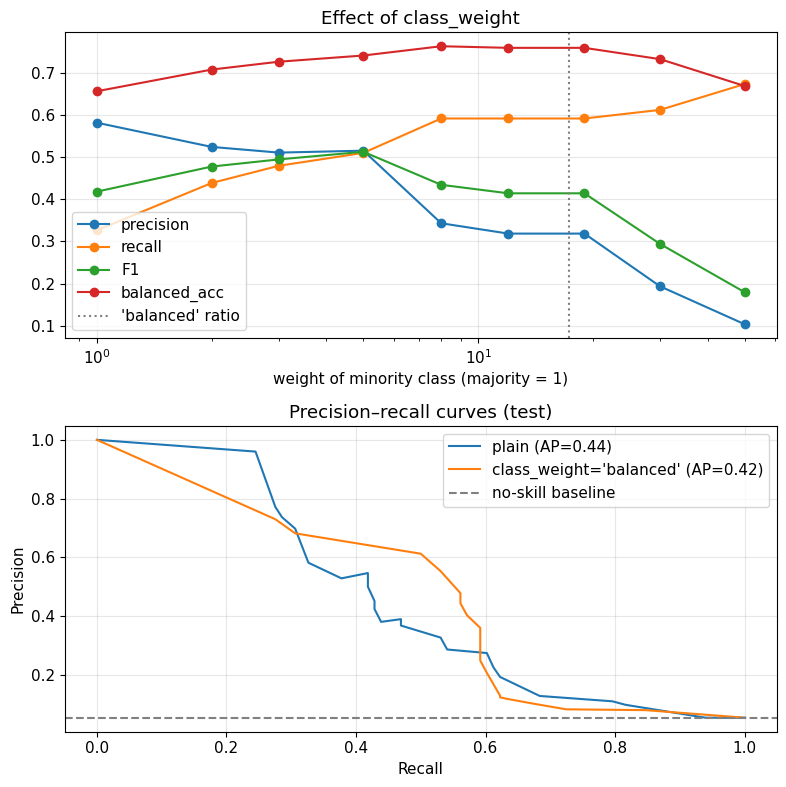

,w_minority,precision,recall,F1,balanced_acc
0,1,0.582,0.327,0.418,0.657
1,2,0.524,0.439,0.478,0.708
2,3,0.511,0.480,0.495,0.727
3,5,0.515,0.510,0.513,0.741
4,8,0.343,0.592,0.434,0.763
5,12,0.319,0.592,0.414,0.759
6,19,0.319,0.592,0.414,0.759
7,30,0.194,0.612,0.294,0.733
8,50,0.104,0.673,0.180,0.669


In [ ]:
w_values = [1, 2, 3, 5, 8, 12, 19, 30, 50]
rows = []
for w in w_values:
    m = DecisionTreeClassifier(class_weight={0: 1, 1: w}, **tree_params).fit(Xi_train, yi_train)
    yp = m.predict(Xi_test)
    rows.append({'w_minority': w, 'precision': precision_score(yi_test, yp, zero_division=0),
                 'recall': recall_score(yi_test, yp), 'F1': f1_score(yi_test, yp),
                 'balanced_acc': balanced_accuracy_score(yi_test, yp)})
cw = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 1, figsize=(8, 8))
for col in ['precision', 'recall', 'F1', 'balanced_acc']:
    axes[0].plot(cw.w_minority, cw[col], 'o-', label=col)
axes[0].axvline(len(X_maj) / len(X_min), color='gray', ls=':', label="'balanced' ratio")
axes[0].set_xscale('log'); axes[0].set_xlabel('weight of minority class (majority = 1)')
axes[0].set_title('Effect of class_weight'); axes[0].legend(); axes[0].grid(alpha=.3)

#--precision-recall curves
for name, model in [('plain', plain), ("class_weight='balanced'", weighted)]:
    pr, rc, _ = precision_recall_curve(yi_test, model.predict_proba(Xi_test)[:, 1])
    axes[1].plot(rc, pr, label=f"{name} (AP={average_precision_score(yi_test, model.predict_proba(Xi_test)[:,1]):.2f})")
axes[1].axhline(yi_test.mean(), color='gray', ls='--', label='no-skill baseline')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision–recall curves (test)')
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
cw.round(3)

As the minority weight grows, recall rises and precision falls. F1 peaks at a **moderate** weight – here well below the `'balanced'` ratio – so the weight should be tuned with cross-validation like any other hyperparameter.

**Good practice for imbalanced data**

* Split with `stratify=y` and use `StratifiedKFold` for cross-validation.
* Resample **only the training data**, never before the train/test split – otherwise duplicated minority points leak into the test set and scores become optimistic. Inside cross-validation, put the resampler in an `imblearn.pipeline.Pipeline` so it is re-applied in each fold.
* Tune hyperparameters with a suitable `scoring` (e.g. `'f1'`, `'balanced_accuracy'`, `'average_precision'`), not `'accuracy'`.
* Report the confusion matrix and per-class metrics.

The optional cell below shows SMOTE (synthetic minority over-sampling) with `imbalanced-learn`, if it is installed (`pip install imbalanced-learn`).

In [ ]:
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    smote_tree = ImbPipeline([('smote', SMOTE(random_state=SEED)),
                              ('tree', DecisionTreeClassifier(**tree_params))])
    #--SMOTE is applied inside each CV fold only
    cv_f1 = cross_val_score(smote_tree, Xi_train, yi_train, cv=cvs, scoring='f1')
    smote_tree.fit(Xi_train, yi_train)
    yp = smote_tree.predict(Xi_test)
    print(f"SMOTE + tree: CV F1 = {cv_f1.mean():.3f}; test recall = {recall_score(yi_test, yp):.3f}, "
          f"precision = {precision_score(yi_test, yp):.3f}, F1 = {f1_score(yi_test, yp):.3f}")
except ImportError:
    print("imbalanced-learn not installed: run  !pip install imbalanced-learn  to try SMOTE.")

SMOTE + tree: CV F1 = 0.375; test recall = 0.653, precision = 0.267, F1 = 0.379


---
# 5. Ensemble learning

## 5.1 What is ensemble learning?

**Ensemble learning** combines the predictions of many models (*base learners*, here trees) into a single prediction – by averaging (regression) or voting (classification).

The idea is the "wisdom of the crowd": if the individual models are reasonably accurate and make **different** errors, the errors partly cancel out, so the ensemble is more accurate and more stable than any single member.

Ensemble methods differ in how they make the members different and how they combine them:

* **Bagging** – train models in **parallel** on random bootstrap samples and average them → reduces **variance**. Random forests belong here.
* **Boosting** – train models **sequentially**, each focusing on the errors of the previous ones → reduces **bias**.
* **Stacking / voting** – combine **different types** of models by voting or with a meta-model.

Single decision trees have low bias but **high variance** (Section 2.5), which makes them ideal members for bagging. The rest of this section focuses on **random forests**; the other methods are summarised briefly in Section 5.8.

## 5.2 Random forests: how they work

1. **Bagging (bootstrap aggregating).** Draw $B$ bootstrap samples (with replacement) from the training data, fit a deep tree on each, and average their predictions (regression) or take a majority/probability vote (classification). Averaging $B$ predictions, each with variance $\sigma^2$ and pairwise correlation $\rho$, gives variance
$$\rho\sigma^2 + \frac{1-\rho}{B}\sigma^2 .$$
More trees shrink the second term, but the first remains if the trees are correlated.
2. **Random feature selection.** At **each split**, a random forest considers only a random subset of `max_features` features (typically $\sqrt{p}$ for classification). Strong predictors can no longer dominate every tree, so the trees are **de-correlated** ($\rho$ falls) and the average has lower variance.
3. **Out-of-bag (OOB) estimate.** Each bootstrap sample leaves out about 37% of the data. Predicting each observation using only the trees that did not see it gives a free validation score (`oob_score=True`).

## 5.3 Random forest vs CART: classification (breast cancer)

We compare, with **repeated stratified 5-fold CV** (5 × 5 = 25 scores per model, so we see the spread as well as the mean):

* the default, fully grown CART tree,
* the CART tree tuned by `GridSearchCV` in Section 2.5,
* bagged trees (`BaggingClassifier`, all features at every split),
* a random forest with default settings.

CART (default)   accuracy = 0.931 ± 0.025   (2.6s)
CART (tuned)     accuracy = 0.929 ± 0.027   (0.4s)
Bagged trees     accuracy = 0.957 ± 0.021   (62.4s)
Random forest    accuracy = 0.957 ± 0.021   (22.2s)


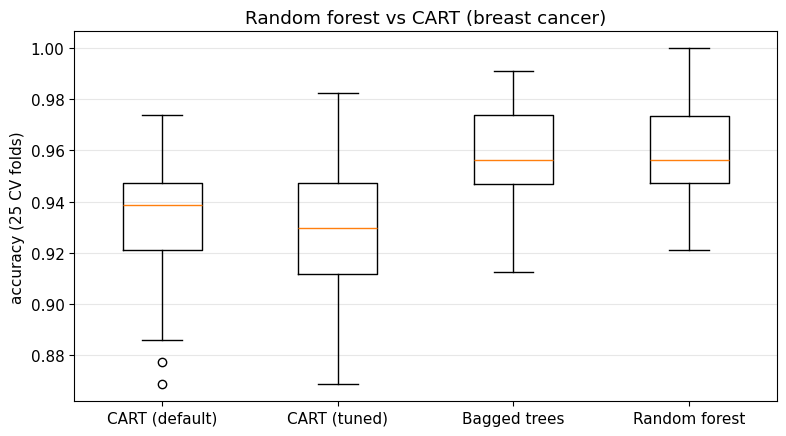


Test accuracy  tuned CART: 0.944   random forest: 0.958
Test ROC-AUC   tuned CART: 0.941   random forest: 0.995


In [ ]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
models = {
    'CART (default)': DecisionTreeClassifier(random_state=SEED),
    'CART (tuned)': DecisionTreeClassifier(random_state=SEED, **grid.best_params_),
    'Bagged trees': BaggingClassifier(DecisionTreeClassifier(), n_estimators=300,
                                      random_state=SEED, n_jobs=-1),
    'Random forest': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}
cv_scores = {}
for name, m in models.items():
    t0 = time.time()
    cv_scores[name] = cross_val_score(m, Xc, yc, cv=rcv, scoring='accuracy', n_jobs=-1)
    print(f"{name:<16} accuracy = {cv_scores[name].mean():.3f} ± {cv_scores[name].std():.3f}   ({time.time()-t0:.1f}s)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()))
ax.set_ylabel('accuracy (25 CV folds)'); ax.set_title('Random forest vs CART (breast cancer)')
ax.grid(alpha=.3, axis='y'); plt.tight_layout(); plt.show()

#--held-out test set
rf_c = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(Xc_train, yc_train)
print(f"\nTest accuracy  tuned CART: {best_cart.score(Xc_test, yc_test):.3f}   random forest: {rf_c.score(Xc_test, yc_test):.3f}")
print(f"Test ROC-AUC   tuned CART: {roc_auc_score(yc_test, best_cart.predict_proba(Xc_test)[:,1]):.3f}   "
      f"random forest: {roc_auc_score(yc_test, rf_c.predict_proba(Xc_test)[:,1]):.3f}")

The ensembles have a clearly **higher mean** accuracy than both CART trees: a default random forest beats even the carefully tuned single tree. Notice also that the "tuned" tree is not reliably better than the default one on new folds – hyperparameters chosen on one noisy CV split of a high-variance model do not transfer well, which is another symptom of the instability shown in Section 2.5. On this small dataset bagging and the random forest score about the same (the forest is faster because it examines fewer features per split); the extra benefit of random feature selection shows up in the `max_features` experiments of Section 5.5. The ROC-AUC gap is larger still, because averaging hundreds of trees gives smooth, well-ranked probabilities, while a single tree outputs only a few distinct leaf proportions.

## 5.4 Random forest vs CART: regression (California housing)

In [ ]:
t0 = time.time()
rf_r = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED, oob_score=True).fit(Xh_train, yh_train)
rf_time = time.time() - t0
reg_cmp = pd.DataFrame({
    'model': ['CART max_depth=4', 'CART (ccp-pruned, Sec 3.3)', 'Random forest (200 trees)'],
    'test RMSE (k$)': [rmse(yh_test, reg.predict(Xh_test)), cart_reg_rmse, rmse(yh_test, rf_r.predict(Xh_test))],
    'test R²': [r2_score(yh_test, reg.predict(Xh_test)), r2_score(yh_test, pruned_reg.predict(Xh_test)),
                r2_score(yh_test, rf_r.predict(Xh_test))],
}).set_index('model').round(3)
print(f"Random forest OOB R² = {rf_r.oob_score_:.3f} (close to the test R², with no separate validation set); fit time {rf_time:.1f}s")
reg_cmp

Random forest OOB R² = 0.810 (close to the test R², with no separate validation set); fit time 40.5s


,test RMSE (k$),test R²
model,,
CART max_depth=4,80.151,0.510
"CART (ccp-pruned, Sec 3.3)",60.970,0.716
Random forest (200 trees),50.374,0.806


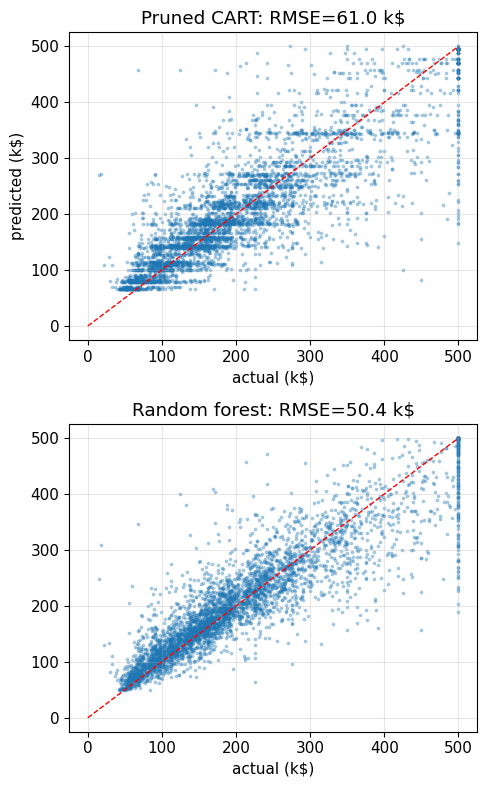

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(5, 8), sharey=True)
for ax, (name, m) in zip(axes, [('Pruned CART', pruned_reg), ('Random forest', rf_r)]):
    yp = m.predict(Xh_test)
    ax.scatter(yh_test, yp, s=3, alpha=.3)
    ax.plot([0, 500], [0, 500], 'r--', lw=1)
    ax.set_title(f'{name}: RMSE={rmse(yh_test, yp):.1f} k$')
    ax.set_xlabel('actual (k$)'); ax.grid(alpha=.3)
axes[0].set_ylabel('predicted (k$)')
plt.tight_layout(); plt.show()

The pruned tree's predictions form horizontal bands (one per leaf); the forest's averaged predictions are much closer to the diagonal and the RMSE drops substantially.

## 5.5 Tunable parameters of a random forest

| Parameter | Meaning | Typical guidance |
|---|---|---|
| `n_estimators` | Number of trees | More is never worse for accuracy, only slower; gains flatten after a few hundred |
| `max_features` | Features tried at each split | Key de-correlation knob. Defaults: `'sqrt'` (classifier), `1.0` = all features (regressor); try `'sqrt'`, `'log2'`, 0.3–0.5 |
| `max_depth`, `min_samples_leaf`, `min_samples_split` | Size of each tree | Forests usually use deep trees; larger leaves give smoother, faster models |
| `max_samples` | Size of each bootstrap sample | Smaller → more diverse, faster trees |
| `bootstrap`, `oob_score` | Bootstrap sampling and OOB evaluation | `oob_score=True` gives a free validation estimate |
| `class_weight` | `'balanced'` or `'balanced_subsample'` (weights recomputed per bootstrap sample) | For imbalanced data |
| `n_jobs`, `random_state` | Parallelism, reproducibility | `n_jobs=-1` uses all cores |


## 5.6 Interpretability: feature importance

We lose the single readable tree, but forests still tell us which features matter:

* **Impurity-based importance** (`feature_importances_`): total impurity decrease contributed by each feature, averaged over trees. Fast, but biased towards continuous/high-cardinality features and computed on training data.
* **Permutation importance**: drop in test score when a feature's values are randomly shuffled. Slower but more reliable.

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


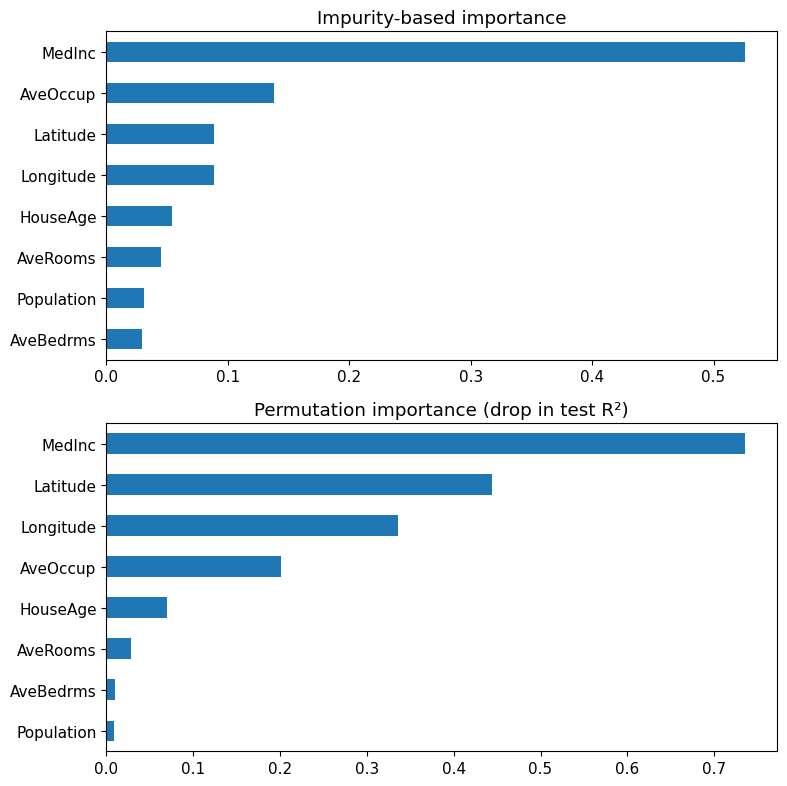

In [ ]:
imp = pd.Series(rf_r.feature_importances_, index=data.columns)
perm = permutation_importance(rf_r, Xh_test, yh_test, n_repeats=5,
                                    random_state=SEED, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=data.columns)

fig, axes = plt.subplots(2, 1, figsize=(8, 8))
imp.sort_values().plot.barh(ax=axes[0], title='Impurity-based importance')
perm_imp.sort_values().plot.barh(ax=axes[1], title='Permutation importance (drop in test R²)')
plt.tight_layout(); plt.show()

## 5.7 Random forests on the imbalanced data

Forests can also be combined with the imbalance remedies of Section 4. `class_weight='balanced_subsample'` recomputes the class weights on each tree's bootstrap sample. Forests also give smoother probabilities, which makes threshold moving work better.

In [ ]:
rf_imb = {
    'RF (no weighting)': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "RF class_weight='balanced_subsample'": RandomForestClassifier(
        n_estimators=300, class_weight='balanced_subsample', min_samples_leaf=5,
        random_state=SEED, n_jobs=-1),
}
rows = results[:2]  #--plain and class-weighted trees from Section 4.3
for name, m in rf_imb.items():
    m.fit(Xi_train, yi_train)
    p = m.predict_proba(Xi_test)[:, 1]
    rows.append(evaluate(name, yi_test, (p >= 0.5).astype(int), p))

#--threshold moving for the unweighted forest, using OOF predictions on the training set
oof_rf = cross_val_predict(RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
                           Xi_train, yi_train, cv=cvs, method='predict_proba')[:, 1]
pr, rc, th = precision_recall_curve(yi_train, oof_rf)
t_rf = th[np.argmax(2*pr[:-1]*rc[:-1]/(pr[:-1]+rc[:-1]+1e-12))]
p = rf_imb['RF (no weighting)'].predict_proba(Xi_test)[:, 1]
rows.append(evaluate(f'RF, threshold={t_rf:.2f}', yi_test, (p >= t_rf).astype(int), p))
pd.DataFrame(rows).set_index('model').round(3)

,accuracy,balanced_acc,precision(1),recall(1),F1(1),PR-AUC
model,,,,,,
1. plain tree,0.948,0.679,0.529,0.378,0.440,0.438
2. class_weight='balanced',0.909,0.759,0.319,0.592,0.414,0.417
RF (no weighting),0.962,0.667,0.892,0.337,0.489,0.582
RF class_weight='balanced_subsample',0.958,0.718,0.677,0.449,0.540,0.605
"RF, threshold=0.30",0.958,0.738,0.658,0.490,0.561,0.582


The forest's **PR-AUC** is much higher than a single tree's – it ranks minority cases far better. With the default 0.5 threshold the unweighted forest is very precise but still misses many minority cases; combining it with `class_weight='balanced_subsample'` or a tuned threshold raises recall and gives the best F1 of all models in this notebook.

## 5.8 Other ensemble methods (brief overview)

Random forests are only one ensemble method. The others, in brief:

* **Extra Trees** (`ExtraTreesClassifier/Regressor`) – like a random forest, but split thresholds are also chosen at random; faster, sometimes even lower variance.
* **AdaBoost** (`AdaBoostClassifier`) – fits shallow trees sequentially, up-weighting misclassified samples.
* **Gradient boosting** (`GradientBoostingClassifier`, `HistGradientBoostingClassifier`, XGBoost, LightGBM, CatBoost) – each new tree fits the residual errors of the current ensemble; often the most accurate method on tabular data, but needs more tuning (`learning_rate`, `n_estimators`, `max_depth`).
* **Voting / stacking** (`VotingClassifier`, `StackingClassifier`) – combine different model types (e.g. tree + logistic regression + SVM).

| Method | How members differ | Trained | Mainly reduces |
|---|---|---|---|
| Bagging / Random forest / Extra Trees | bootstrap samples (+ random features / thresholds) | in parallel | variance |
| AdaBoost / Gradient boosting | re-weighted samples / residuals | sequentially | bias (and variance) |
| Voting / Stacking | different algorithms | in parallel, then combined | both |